In [13]:
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

## 1. Загрузка данных

In [14]:
users = pd.read_csv('users.csv')
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


In [15]:
payments = pd.read_csv('payments.csv')
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaN,NaN
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaN,NaN
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaN,NaN
3,5004,1004.0,A,2024-04-09 16:02:00,NaN,NaN,NaN
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 2. Разведывательный анализ (EDA) и предобработка данных
Удаляем аномалии (некорректный возраст < 18 и > 100 лет, пропуски в ключевых полях) и объединяем таблицы.

In [16]:
# Очищаем пользователей от аномалий возраста
clean_users = users[(users['age'] >= 18) & (users['age'] <= 100) & users['group'].notnull() & users['city'].notnull()].copy()

# Очищаем платежи от пропущенных user_id
clean_payments = payments[payments['user_id'].notnull()].copy()

# Объединяем таблицы по user_id
df_full = pd.merge(clean_payments, clean_users, on='user_id', how='inner', suffixes=('_payment', '_user'))

print("Размер объединенного датасета после очистки:", df_full.shape)
df_full.head()

Размер объединенного датасета после очистки: (2659, 11)


,payment_id,user_id,group_payment,step1_opened,step2_entered,step3_confirmed,step4_success,group_user,age,city,device_type
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaN,NaN,A,31,Москва,ios
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaN,NaN,A,31,Москва,ios
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaN,NaN,A,25,Москва,android
3,5004,1004.0,A,2024-04-09 16:02:00,NaN,NaN,NaN,A,20,Москва,ios
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00,A,20,Москва,ios


## 3. Расчет ключевой метрики (Конверсия из шага 1 в шаг 4)

In [17]:
# Проверяем на уровне пользователя, был ли хотя бы один успешный платеж (шаг 4)
user_level = df_full.groupby('user_id').agg({
    'group_user': 'first',
    'step4_success': lambda x: x.notnull().any()
}).reset_index()

# Считаем конверсию по группам
conversion_summary = user_level.groupby('group_user')['step4_success'].agg(
    total_users='count',
    converted_users='sum',
    conversion_rate='mean'
).reset_index()

conversion_summary['conversion_rate'] = conversion_summary['conversion_rate'] * 100
conversion_summary

,group_user,total_users,converted_users,conversion_rate
0,A,750,493,65.733333
1,B,750,603,80.400000


## 4. Статистическая проверка гипотез (Z-тест для долей)

In [18]:
successes = [
    conversion_summary.loc[conversion_summary['group_user'] == 'B', 'converted_users'].values[0],
    conversion_summary.loc[conversion_summary['group_user'] == 'A', 'converted_users'].values[0]
]
nobs = [
    conversion_summary.loc[conversion_summary['group_user'] == 'B', 'total_users'].values[0],
    conversion_summary.loc[conversion_summary['group_user'] == 'A', 'total_users'].values[0]
]

z_stat, p_val = proportions_ztest(successes, nobs)

print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_val:.5e}")

if p_val < 0.05:
    print("\nРезультат статистически значим: отвергаем нулевую гипотезу (H0). Новая форма дает прирост конверсии.")
else:
    print("\nСтатистически значимых различий нет.")

Z-статистика: 6.4024
p-value: 1.52960e-10

Результат статистически значим: отвергаем нулевую гипотезу (H0). Новая форма дает прирост конверсии.


## 5. Визуализация результатов

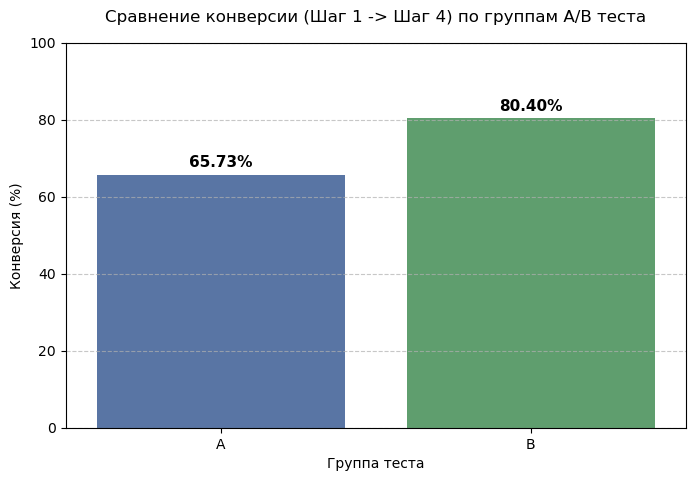

In [19]:
plt.figure(figsize=(8, 5))
sns.barplot(data=conversion_summary, x='group_user', y='conversion_rate', hue='group_user', palette=['#4c72b0', '#55a868'], legend=False)

plt.title('Сравнение конверсии (Шаг 1 -> Шаг 4) по группам A/B теста', fontsize=12, pad=15)
plt.xlabel('Группа теста', fontsize=10)
plt.ylabel('Конверсия (%)', fontsize=10)
plt.ylim(0, 100)

for index, row in conversion_summary.iterrows():
    plt.text(index, row['conversion_rate'] + 2, f"{row['conversion_rate']:.2f}%", 
             color='black', ha='center', fontweight='bold', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 6. Итоговые выводы и бизнес-рекомендации

1. **Результаты теста:** 
   - Конверсия из открытия формы (шаг 1) в успешную оплату (шаг 4) в контрольной группе (A) составила **65.73%**.
   - В тестовой группе (B) с упрощенной формой оплаты конверсия выросла до **80.40%**.
   - Прирост составил **~14.67 процентных пункта**.

2. **Статистическая значимость:** 
   - Проведенный Z-тест для долей показал высокую статистическую значимость ($p\text{-value} < 1.53 \times 10^{-10}$ при $\alpha = 0.05$). Нулевая гипотеза об отсутствии различий уверенно отвергается.

3. **Рекомендация:** 
   - Новая упрощенная форма ЖКУ демонстрирует мощный положительный эффект на пользовательский опыт и ключевую метрику воронки. Рекомендуется **полностью раскатить изменения на всю аудиторию**.